In [7]:
%env ICS3202_RUN_HELD_OUT=1
%pip install -q rapidfuzz

env: ICS3202_RUN_HELD_OUT=1


# Route 125 stop finder · Final working notebook

In [8]:
import importlib
import json
from hashlib import sha256
import os
from pathlib import Path
from urllib.request import urlretrieve
from zipfile import ZipFile

import numpy as np
import pandas as pd
from IPython.display import display
from rapidfuzz.distance import Levenshtein

ROOT = Path.cwd()
OUTPUT_DIR = ROOT / 'ics3202_outputs'
OUTPUT_DIR.mkdir(exist_ok=True)
RUN_HELD_OUT = os.environ.get('ICS3202_RUN_HELD_OUT') == '1'
ARCHIVE = ROOT / 'Bradley_Reviewed_Data_v1.zip'
EXPECTED_ARCHIVE_HASH = 'e54a348c6af58c14e659ed5c50f85fc1dae6904ee3605ebae28d187c76050d83'


def read_zip_csv(zip_file, name, **kwargs):
    """Read one CSV member of an open zip, keeping every value as text."""
    with zip_file.open(name) as member:
        return pd.read_csv(member, dtype=str, keep_default_na=False, **kwargs)

assert ARCHIVE.is_file(), f'Upload {ARCHIVE.name} to {ROOT} in the Files pane.'
archive_hash = sha256(ARCHIVE.read_bytes()).hexdigest()
assert archive_hash == EXPECTED_ARCHIVE_HASH, f'Archive hash {archive_hash} does not match the team copy.'
with ZipFile(ARCHIVE) as archive:
    catalogue = read_zip_csv(archive, 'route125_catalogue_v1.csv')
    groups = read_zip_csv(archive, 'selected_name_groups_v1.csv')
    assignments = read_zip_csv(archive, 'split_assignments_v1.csv')
    reviewed = read_zip_csv(archive, 'reviewed_queries_v1.csv')
    ambiguity = read_zip_csv(archive, 'ambiguity_challenge_v1.csv')
    archived_pairs = read_zip_csv(archive, 'query_candidate_pairs_v1.csv')

assert (len(catalogue), len(reviewed), len(ambiguity), len(archived_pairs)) == (79, 94, 6, 3803)
print(f'Reviewed archive loaded: {len(catalogue)} catalogue rows | {len(reviewed)} accepted queries | '
      f'{len(ambiguity)} ambiguity rows | {len(archived_pairs):,} pairs')

Reviewed archive loaded: 79 catalogue rows | 94 accepted queries | 6 ambiguity rows | 3,803 pairs


## Shared name features

The baseline and the model use the same name rules. The app uses this module to reproduce the notebook's scores. The feature-file hash identifies the exact version used.

In [9]:
feature_source = r"""import unicodedata

import numpy as np
import pandas as pd
from rapidfuzz.distance import Levenshtein


FEATURE_COLUMNS = (
    'exact_match',
    'char_similarity',
    'token_jaccard',
    'relative_length_difference',
)
TIE_ATOL = 1e-12


def normalize_name(name):
    if pd.isna(name):
        return ''
    return ' '.join(unicodedata.normalize('NFKC', str(name)).lower().split())


def calculate_features(query, candidate):
    query = normalize_name(query)
    candidate = normalize_name(candidate)
    if not query or not candidate:
        raise ValueError('Query and candidate names must not be blank.')
    query_words = set(query.split())
    candidate_words = set(candidate.split())
    return {
        'exact_match': int(query == candidate),
        'char_similarity': Levenshtein.normalized_similarity(query, candidate),
        'token_jaccard': len(query_words & candidate_words) / len(query_words | candidate_words),
        'relative_length_difference': abs(len(query) - len(candidate)) / max(len(query), len(candidate)),
    }


def build_features(pairs):
    rows = (
        calculate_features(query, candidate)
        for query, candidate in zip(pairs['normalized_query'], pairs['normalized_candidate_name'])
    )
    return pd.DataFrame(rows, columns=FEATURE_COLUMNS, index=pairs.index)


def positive_scores(pipeline, features):
    positive_column = list(pipeline.classes_).index(1)
    return pipeline.predict_proba(features)[:, positive_column]


def top_mask(scores):
    scores = np.asarray(scores, dtype=float)
    return np.isclose(scores, scores.max(), rtol=0, atol=TIE_ATOL)


def score_live_candidates(query, candidates, pipeline):
    features = build_features(pd.DataFrame({
        'normalized_query': query,
        'normalized_candidate_name': candidates['normalized_stop_name'],
    }, index=candidates.index))
    return features, positive_scores(pipeline, features)
"""
feature_path = ROOT / 'stop_finder_features.py'
feature_path.write_bytes(feature_source.encode('utf-8'))
print('Wrote', feature_path.name)

Wrote stop_finder_features.py


## Bradley · Route data and cleaning

Match a typed stop name to the right stop ID on route 125 in the stated direction. The archived queries are team-authored examples. IDs stay as text when the tables are loaded.

In [10]:
FEED_NAME = 'mdb-1815-202406071505.zip'
FEED = ROOT / FEED_NAME
FEED_URL = f'https://files.mobilitydatabase.org/mdb-1815/mdb-1815-202406071505/{FEED_NAME}'
FEED_HASH = 'd18b4890281efeb54b1bb02e45db8adc26b54c6f39c991124ef5a896aa0c68c4'
if not FEED.is_file():
    urlretrieve(FEED_URL, FEED)
assert sha256(FEED.read_bytes()).hexdigest() == FEED_HASH, 'The feed is not the expected snapshot.'

with ZipFile(FEED) as feed:
    stops = read_zip_csv(feed, 'stops.txt', usecols=['stop_id', 'stop_name'])
    trips = read_zip_csv(feed, 'trips.txt', usecols=['trip_id', 'route_id', 'direction_id'])
    stop_times = read_zip_csv(feed, 'stop_times.txt', usecols=['trip_id', 'stop_id'])

for name, table in (('stops', stops), ('trips', trips), ('stop_times', stop_times)):
    print(name, table.shape)
    display(table.head(3))

route_trips = trips[trips['route_id'].eq('50205012511')]
keys = ['route_id', 'direction_id', 'stop_id']
from_feed = (
    stop_times.merge(route_trips, on='trip_id', validate='many_to_one')[keys]
    .drop_duplicates()
    .merge(stops, on='stop_id', validate='many_to_one')
)
pd.testing.assert_frame_equal(
    from_feed.sort_values(keys).reset_index(drop=True),
    catalogue[from_feed.columns].sort_values(keys).reset_index(drop=True),
)
per_direction = from_feed.groupby('direction_id').size().to_dict()
print(f'Feed hash verified. {len(from_feed)} route memberships and {from_feed.stop_id.nunique()} '
      f'distinct stops match the catalogue. Stops per direction: {per_direction}')

stops (4284, 2)


,stop_id,stop_name
0,0001RLW,Railways
1,0002KOJ,Koja
2,0003NGR,Ngara


trips (272, 3)


,route_id,trip_id,direction_id
0,10000107D11,1107D110,0
1,10000107D11,1107D111,1
2,10000114011,10114110,0


stop_times (7533, 2)


,trip_id,stop_id
0,10106110,0110BAA
1,10106110,0110BNI
2,10106110,0110UMK


Feed hash verified. 79 route memberships and 78 distinct stops match the catalogue. Stops per direction: {'0': 42, '1': 37}


### Candidate pairs and split checks

The reviewed archive supplies the accepted and ambiguous examples and the fixed group assignments. Rebuild the candidate pairs by comparing each accepted query with every stop in its route and direction.

In [11]:
import re
import unicodedata

Q_ID, Q_GROUP, Q_TEXT = 'query_id', 'name_group_id', 'input_text'
Q_ROUTE, Q_DIR, Q_STOP = 'route_id', 'direction_id', 'expected_stop_id'
Q_STATUS = 'status'

def normalize(s):
    s = unicodedata.normalize('NFKC', s).lower().strip()
    return re.sub(r'\s+', ' ', s)

split_df = assignments
acc = reviewed.merge(split_df, on=Q_GROUP, validate='many_to_one')
acc['norm_query'] = acc[Q_TEXT].map(normalize)
acc['group_name'] = acc[Q_GROUP].map(groups.set_index(Q_GROUP)['normalized_stop_name'])
assert acc['group_name'].notna().all()

log_path = ROOT / 'cleaning_log_v1.csv'
assert log_path.is_file(), f'Place {log_path.name} in {ROOT}.'
cleaning_log = pd.read_csv(log_path, dtype=str, keep_default_na=False)
assert cleaning_log[Q_ID].is_unique
assert not set(cleaning_log[Q_ID]) & (set(reviewed[Q_ID]) | set(ambiguity[Q_ID]))

In [12]:
rows = []
for r in acc.to_dict('records'):
    mask = (catalogue['route_id'] == r[Q_ROUTE]) & (catalogue['direction_id'] == r[Q_DIR])
    for c in catalogue[mask].to_dict('records'):
        rows.append({
            'pair_id':                  r[Q_ID] + '__' + c['stop_id'],
            'query_id':                 r[Q_ID],
            'name_group_id':            r[Q_GROUP],
            'route_id':                 r[Q_ROUTE],
            'direction_id':             r[Q_DIR],
            'query_text':               r[Q_TEXT],
            'normalized_query':         r['norm_query'],
            'candidate_stop_id':        c['stop_id'],
            'candidate_stop_name':      c['stop_name'],
            'normalized_candidate_name': c['normalized_stop_name'],
            'is_match':                 int(c['stop_id'] == r[Q_STOP]),
        })

pairs = (
    pd.DataFrame(rows)
      .merge(split_df, on='name_group_id', how='left')
      .sort_values('pair_id')
      .reset_index(drop=True)
)

print('queries:', pairs['query_id'].nunique(), 'pairs:', len(pairs))
print(pairs['is_match'].value_counts())
assert pairs['query_id'].nunique() == 94 and len(pairs) == 3803


queries: 94 pairs: 3803
is_match
0    3709
1      94
Name: count, dtype: int64


In [13]:
assert pairs['pair_id'].is_unique
assert pairs['split'].notna().all()
assert pairs['is_match'].isin([0, 1]).all()
assert pairs.groupby('query_id')['is_match'].sum().eq(1).all()
assert not pairs.duplicated(['query_id', 'candidate_stop_id']).any()
assert pairs.groupby('name_group_id')['split'].nunique().max() == 1
assert pairs.groupby('normalized_query')['split'].nunique().max() == 1
assert pairs.groupby('query_id')[['route_id', 'direction_id',
'name_group_id', 'split']].nunique().max().max() == 1
assert acc[Q_STATUS].eq('ACCEPTED').all()
assert set(pairs['name_group_id']) <= set(split_df['name_group_id'])
assert groups['normalized_stop_name'].is_unique
print('all checks passed')
print(pairs.groupby('split')['query_id'].nunique())

all checks passed
split
test          21
train         52
validation    21
Name: query_id, dtype: int64


## EDA observations
Four measured observations with explanations.


count    30.000000
mean      3.133333
std       1.074255
min       0.000000
25%       3.000000
50%       3.000000
75%       4.000000
max       4.000000
dtype: float64
name_group_id
G10    1
G22    0
G23    0
dtype: int64
split
test          21
train         52
validation    21
Name: query_id, dtype: int64
direction_id
0    42
1    37
Name: stop_id, dtype: int64
stop_id
1    46
2    16
Name: count, dtype: int64


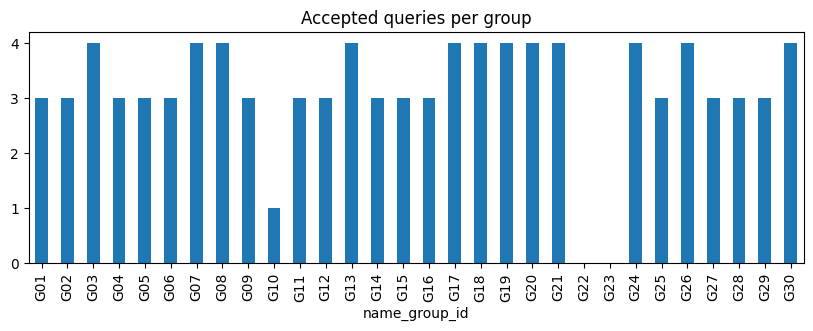

In [14]:
per_group = (acc.groupby(Q_GROUP).size()
              .reindex(groups['name_group_id'], fill_value=0))
print(per_group.describe())
print(per_group[per_group <= 1])
print(acc.groupby('split')[Q_ID].nunique())
per_group.plot(kind='bar', figsize=(10, 3), title='Accepted queries per group')

print(catalogue.groupby('direction_id')['stop_id'].nunique())
names_per = catalogue.groupby('normalized_stop_name')['stop_id'].nunique()
print(names_per.value_counts())


---
*How many names contain a slash, and how long are names in words?*


In [15]:
print('names with a slash:',
catalogue['normalized_stop_name'].str.contains('/').sum())
print(catalogue['normalized_stop_name'].str.split().str.len().describe())


names with a slash: 24
count    79.000000
mean      1.822785
std       0.957554
min       1.000000
25%       1.000000
50%       2.000000
75%       2.000000
max       5.000000
Name: normalized_stop_name, dtype: float64


**Explanation:** 24 of the 79 catalogue rows contain a slash, so about 30% of stops are affected. Names are short, with a median of 2 words, and at least a quarter are a single word. The rules keep slashes inside tokens, so a name like `bomas/galleria` counts as one word. A query typed with a space instead of the slash shares no token with it, so the token-based score will treat them as different. For one-word names, a single typo removes all token overlap.


---
*How many rows were removed and why?*


In [16]:
print(cleaning_log['reason'].value_counts().to_string())
print('Ambiguous:', len(ambiguity))
print('Accepted:', len(acc))
total = len(acc) + len(ambiguity) + len(cleaning_log)
assert total == 120
print('Total received:', total, '| kept:', f'{len(acc) / total:.1%}')

reason
status REJECTED                                13
failed check: stop not in route/direction;      7
Ambiguous: 6
Accepted: 94
Total received: 120 | kept: 78.3%


Of 120 reviewed queries, 94 were kept, 6 were set aside as ambiguous and 13 were rejected during review. A further 7 were excluded because their expected stop ID was absent from the stated route and direction. Their reasons were logged, and they were left out of the candidate pairs and model evaluation.

---
*Candidate pools and how many wrong candidates each query faces*


In [17]:
print(pairs['is_match'].value_counts())
print(pairs.groupby('direction_id')['candidate_stop_id'].nunique())
match_share = pairs['is_match'].mean()
print(f'match share: {match_share:.2%} | all-"no match" accuracy: {1 - match_share:.2%}')
print('queries:', pairs['query_id'].nunique(), '| pair rows:', len(pairs))


is_match
0    3709
1      94
Name: count, dtype: int64
direction_id
0    42
1    37
Name: candidate_stop_id, dtype: int64
match share: 2.47% | all-"no match" accuracy: 97.53%
queries: 94 | pair rows: 3803


**Explanation:** Each query is paired with every stop in its direction, so each has 1 correct candidate and 36 or 41 wrong ones. Matches are only 2.47% of the 3,803 pair rows. A model that always answered 'no match' would score about 97.5% accuracy, so accuracy is misleading here. Precision, recall and per-query success matter more. I report 94 queries separately from 3,803 pair rows, since pairs from one query are not independent.


---
*How much shorter or longer are queries than the real name?*


In [18]:
acc['len_ratio'] = acc['norm_query'].str.len() / acc['group_name'].str.len()
display(acc.groupby('example_type')['len_ratio'].describe().round(2))
print('my (Bradley) shortened queries:')
print(acc.loc[acc['author'].eq('Bradley') & acc['example_type'].eq('SHORTENED'),
              'len_ratio'].describe().round(2))


,count,mean,std,min,25%,50%,75%,max
example_type,,,,,,,,
EXACT,28.0,1.00,0.00,1.00,1.00,1.00,1.00,1.00
SHORTENED,14.0,0.58,0.21,0.22,0.51,0.59,0.78,0.83
TYPO,52.0,1.01,0.12,0.80,0.93,1.00,1.17,1.20


my (Bradley) shortened queries:
count    5.00
mean     0.47
std      0.20
min      0.25
25%      0.28
50%      0.53
75%      0.57
max      0.70
Name: len_ratio, dtype: float64


**Explanation:** EXACT queries sit at 1.0 and TYPO queries close to it (median 1.0, range 0.8 to 1.2), while SHORTENED queries are well below. Across both authors, the 14 shortened queries have a median ratio of 0.59, meaning they keep about 59% of the name, and the shortest keeps 22%. My own 5 have a median of 0.53.

## Exact/fuzzy baseline

An exact match between cleaned names scores 2.0. Otherwise the score is the normalized Levenshtein similarity, from 0 to 1. A query counts as correct only if the right stop is alone at the top. Stop scores within `1e-12` of the best are treated as tied.

In [19]:
import importlib, json
import stop_finder_features
importlib.reload(stop_finder_features)  # pick up the file just written, even on a re-run
from stop_finder_features import top_mask
from rapidfuzz.distance import Levenshtein

# the pairs built above must match the verified archive row for row
verified_pairs = archived_pairs
mine = pairs.astype(str).sort_values('pair_id').reset_index(drop=True)
pd.testing.assert_frame_equal(mine[verified_pairs.columns],
                              verified_pairs.sort_values('pair_id').reset_index(drop=True))
print(f'all {len(pairs):,} pairs match the verified archive')


def baseline_scores(rows):
    scored = rows[['query_id', 'query_text', 'candidate_stop_id',
                   'candidate_stop_name', 'is_match']].copy()
    scored['score'] = [
        2.0 if left == right else Levenshtein.normalized_similarity(left, right)
        for left, right in zip(rows['normalized_query'], rows['normalized_candidate_name'])
    ]
    return scored


def baseline_result(rows):
    scored = baseline_scores(rows)
    correct, tied, wrong = [], [], []
    for qid, group in scored.groupby('query_id'):
        first = group.loc[top_mask(group['score'])]
        if len(first) > 1:
            tied.append(qid)
        elif first['is_match'].iloc[0] == 1:
            correct.append(qid)
        else:
            wrong.append(qid)
    return scored, {'pairs': len(rows), 'queries': rows['query_id'].nunique(),
                    'unique_first': len(correct), 'ties': len(tied)}, tied, wrong


val_rows = pairs.loc[pairs['split'].eq('validation')]
val_scored, baseline_validation, val_tied, val_wrong = baseline_result(val_rows)
assert (baseline_validation['pairs'], baseline_validation['queries']) == (832, 21)
print(f"Validation: {baseline_validation['unique_first']} of {baseline_validation['queries']} "
      f"uniquely first, {baseline_validation['ties']} tie(s).")
assert baseline_validation['unique_first'] == 19 and baseline_validation['ties'] == 1

for label, ids in [('Tie (reported separately)', val_tied), ('Wrong stop first', val_wrong)]:
    for qid in ids:
        print(f'\n{label}: {qid}')
        display(val_scored[val_scored['query_id'].eq(qid)]
                .sort_values('score', ascending=False).head(3).round(4))

all 3,803 pairs match the verified archive
Validation: 19 of 21 uniquely first, 1 tie(s).

Tie (reported separately): K010


,query_id,query_text,candidate_stop_id,candidate_stop_name,is_match,score
2296,K010,Nerston,0510WIL,Weston,0,0.7143
2289,K010,Nerston,0510NST,Naston,1,0.7143
2268,K010,Nerston,0500NTU,Nyotu,0,0.2857



Wrong stop first: K016


,query_id,query_text,candidate_stop_id,candidate_stop_name,is_match,score
2492,K016,Nibs,0001RLW,Railways,0,0.2500
2500,K016,Nibs,0501NIB,NIBS/Ongata Rongai,1,0.2222
2512,K016,Nibs,0511BRK,Langata Barracks,0,0.1875


The right stop is alone at the top for 19 of the 21 validation queries.

The tie is K010, `nerston`. Naston and Weston both score 0.7143 because each is two edits from the query, so the rule has no way to pick one. Naston is the correct stop, but a tie does not count as correct.

The other miss is K016, `nibs`. Railways scores 0.25 and the correct NIBS/Ongata Rongai scores 0.222. Levenshtein compares whole strings, so a four-letter query sits closer to a short wrong name than to the long right one. Kate's model gets 20 of 21 on the same queries, with one tie.


## Kate · Feature preparation and training

Use the same archived pairs and fixed split as the baseline. Every query has one correct candidate. The group, normalized query text and query ID each stay in one split.

In [20]:
pairs = archived_pairs.sort_values('pair_id').reset_index(drop=True)
pairs['is_match'] = pairs['is_match'].astype(int)

assert pairs["pair_id"].is_unique and pairs["is_match"].isin([0, 1]).all()
assert pairs.groupby("query_id")["is_match"].sum().eq(1).all()        # one correct stop per query
assert pairs.groupby("name_group_id")["split"].nunique().eq(1).all()  # a group sits in one split
assert pairs.groupby("normalized_query")["split"].nunique().eq(1).all()
assert pairs.groupby("query_id")["split"].nunique().eq(1).all()
# the split in the pairs is the fixed group split from Bradley
split_in_pairs = pairs.drop_duplicates("name_group_id").set_index("name_group_id")["split"]
assert split_in_pairs.eq(assignments.set_index("name_group_id")["split"].loc[split_in_pairs.index]).all()

query_rows = reviewed.merge(assignments, on="name_group_id", validate="many_to_one")
assert set(query_rows["query_id"]) == set(pairs["query_id"])
assert len(pairs) == 3803 and pairs["is_match"].sum() == len(query_rows) == 94

summary = pairs.groupby("split").agg(
    pairs=("pair_id", "size"), queries=("query_id", "nunique"), groups=("name_group_id", "nunique"),
).reindex(["train", "validation", "test"])
assert summary.to_numpy().tolist() == [[2109, 52, 16], [832, 21, 6], [862, 21, 6]]
display(summary)

,pairs,queries,groups
split,,,
train,2109,52,16
validation,832,21,6
test,862,21,6


## Features




*   exact_match: It checks whether the passengers input or query and the catalogue names are exactly the same after normalisation. 1 = Names match exactly while 0 = names are different.
*   char_similarity: measures how similar two strings are by each character. Uses Levenshtein edit distance.1 means identical; a higher score means a higher similarity.
*   token_jaccard: measures how many words two names have in common
*   relative_length_difference: calculates the number of characters in two names and gets the difference, then it divides it by the length of the longer name.



In [ ]:
import unicodedata
import pandas as pd
from rapidfuzz.distance import Levenshtein


def normalize_name(name):
    if pd.isna(name):
        return ""

    name = unicodedata.normalize("NFKC", str(name))

    name = name.lower()

    name = name.strip()

    name = " ".join(name.split())

    return name


# ============================================
# 3. CALCULATE FEATURES FOR ONE PAIR
# ============================================

def calculate_features(query, candidate):
    # Normalize both names before comparing them
    query = normalize_name(query)
    candidate = normalize_name(candidate)

    # Do not calculate features for blank names
    if not query or not candidate:
        raise ValueError(
            "Query and candidate names must not be blank."
        )

    # FEATURE 1: Exact Match
    # 1 if the normalized names are identical; otherwise 0
    exact_match = int(query == candidate)

    # FEATURE 2: Character Similarity
    # Compares characters using normalized Levenshtein similarity.
    # The result is between 0 and 1.
    char_similarity = Levenshtein.normalized_similarity(
        query, candidate
    )

    # FEATURE 3: Token Jaccard Similarity
    # Split names into words and remove repeated words using sets
    query_words = set(query.split())
    candidate_words = set(candidate.split())

    # Count words shared by both names
    common_words = query_words.intersection(candidate_words)

    # Count all distinct words appearing in either name
    all_words = query_words.union(candidate_words)

    # Calculate the proportion of shared words
    token_jaccard = len(common_words) / len(all_words)

    # FEATURE 4: Relative Length Difference
    # Compare the character lengths of the two normalized names
    longer_length = max(len(query), len(candidate))

    relative_length_difference = (
        abs(len(query) - len(candidate)) / longer_length
    )

    # Return the four features in the required order
    return {
        "exact_match": exact_match,
        "char_similarity": char_similarity,
        "token_jaccard": token_jaccard,
        "relative_length_difference": relative_length_difference
    }


# ============================================
# 4. BUILD FEATURES FOR A WHOLE DATAFRAME
# ============================================

def build_features(pairs_dataframe):
    # Column names used in Bradley's reviewed pairs file
    required_columns = ["normalized_query", "normalized_candidate_name"]

    # Check that the required columns exist
    for column in required_columns:
        if column not in pairs_dataframe.columns:
            raise ValueError(
                f"Missing required column: {column}. "
                f"Available columns: {list(pairs_dataframe.columns)}"
            )

    # Store the features calculated for each row
    feature_rows = []

    # Process each query-candidate pair without changing row order
    for _, row in pairs_dataframe.iterrows():

        # Calculate all four features using our existing function
        features = calculate_features(
            row["normalized_query"],
            row["normalized_candidate_name"]
        )

        # Add the results for this pair
        feature_rows.append(features)

    # Define the exact feature column order required by the project
    feature_columns = [
        "exact_match",
        "char_similarity",
        "token_jaccard",
        "relative_length_difference"
    ]

    # Return only the four features, preserving the original index
    features_dataframe = pd.DataFrame(
        feature_rows,
        columns=feature_columns,
        index=pairs_dataframe.index
    )

    return features_dataframe


# ============================================
# 5. TEST THE FUNCTIONS
# ============================================

# Test normalization
print("Normalized name:")
print(normalize_name("  Nafrom  "))

# Test one identical pair
print("\nTest 1: Identical names")
print(calculate_features("Nafrom", "Nafrom"))

# Test one pair with a spelling difference
print("\nTest 2: Names with a spelling difference")
print(calculate_features("nafom", "nafrom"))

# Test build_features using a small example
# This is only a function test, not project training data.
test_pairs = pd.DataFrame({
    "normalized_query": ["Nafrom", "nafom"],
    "normalized_candidate_name": ["Nafrom", "nafrom"]
})

test_features = build_features(test_pairs)

print("\nFeatures for the test pairs:")
print(test_features)

# Check the required feature columns
print("\nFeature columns:")
print(list(test_features.columns))

# Check that the number of output rows matches the input
assert len(test_features) == len(test_pairs)

# Check the exact required column order
assert list(test_features.columns) == [
    "exact_match",
    "char_similarity",
    "token_jaccard",
    "relative_length_difference"
]

print("\nAll feature function tests passed!")


Normalized name:
nafrom

Test 1: Identical names
{'exact_match': 1, 'char_similarity': 1.0, 'token_jaccard': 1.0, 'relative_length_difference': 0.0}

Test 2: Names with a spelling difference
{'exact_match': 0, 'char_similarity': 0.8333333333333334, 'token_jaccard': 0.0, 'relative_length_difference': 0.16666666666666666}

Features for the test pairs:
   exact_match  char_similarity  token_jaccard  relative_length_difference
0            1         1.000000            1.0                    0.000000
1            0         0.833333            0.0                    0.166667

Feature columns:
['exact_match', 'char_similarity', 'token_jaccard', 'relative_length_difference']

All feature function tests passed!


In [22]:
# Test the features using two identical names
result = calculate_features("Nafrom", "Nafrom")

print(result)

{'exact_match': 1, 'char_similarity': 1.0, 'token_jaccard': 1.0, 'relative_length_difference': 0.0}


In [23]:
# Compare the correct stop name with a misspelled query
result = calculate_features("nafom", "nafrom")

print(result)

{'exact_match': 0, 'char_similarity': 0.8333333333333334, 'token_jaccard': 0.0, 'relative_length_difference': 0.16666666666666666}


In [24]:
import importlib
import stop_finder_features

importlib.reload(stop_finder_features)  # pick up the file just written, even on a re-run
from stop_finder_features import (
    FEATURE_COLUMNS, TIE_ATOL, positive_scores, score_live_candidates, top_mask,
)

EXPECTED_FEATURES_HASH = '1053e5bce44c118b6c0af78a3fcf1a36615719451a22f6eda51ad1b8de6fff0a'
features_hash = sha256((ROOT / 'stop_finder_features.py').read_bytes()).hexdigest()
assert features_hash == EXPECTED_FEATURES_HASH, 'stop_finder_features.py changed; the handoff hash will not match.'
assert TIE_ATOL == 1e-12

X = stop_finder_features.build_features(pairs)
X_kate = build_features(pairs)  # Kate's own version from the Features section
pd.testing.assert_frame_equal(X, X_kate, check_exact=True)
assert list(X.columns) == list(FEATURE_COLUMNS) == [
    "exact_match", "char_similarity", "token_jaccard", "relative_length_difference"]
assert np.isfinite(X.to_numpy()).all() and X.ge(0).all().all() and X.le(1).all().all()

train = pairs.loc[pairs['split'].eq('train')].copy()
validation = pairs.loc[pairs['split'].eq('validation')].copy()
print(f'Feature module hash OK. {len(X):,} feature rows; Kate\'s functions agree on every pair.')

Feature module hash OK. 3,803 feature rows; Kate's functions agree on every pair.


## Training-only cross validation

Spellings of the same stop name have to stay on the same side of a fold. If `nafrom` were in the fitting folds and `nafom` in the check fold, the check would partly test a name the model had already seen. `GroupKFold` splits the training pairs into three folds by `name_group_id`, and an assertion confirms the fit and check sets share no group. Each fold gets a new pipeline (a scaler, then logistic regression with balanced class weights). Pair metrics in each fold use the default 0.5 cutoff.


In [25]:
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import confusion_matrix, precision_recall_fscore_support
from sklearn.model_selection import GroupKFold
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler


def new_model():
    return make_pipeline(StandardScaler(), LogisticRegression(class_weight='balanced', max_iter=1000))


def pair_report(labels, predictions):
    precision, recall, f1, _ = precision_recall_fscore_support(
        labels, predictions, average='binary', zero_division=0,
    )
    return {'precision': precision, 'recall': recall, 'f1': f1}


fold_reports = []
for fold, (fit_pos, check_pos) in enumerate(
    GroupKFold(n_splits=3).split(train, groups=train['name_group_id']), start=1,
):
    fit_rows = train.iloc[fit_pos]
    check_rows = train.iloc[check_pos]
    assert not set(fit_rows['name_group_id']) & set(check_rows['name_group_id'])
    fold_model = new_model().fit(X.loc[fit_rows.index], fit_rows['is_match'])
    predictions = fold_model.predict(X.loc[check_rows.index])
    fold_reports.append({'fold': fold, 'check_groups': check_rows['name_group_id'].nunique(),
                         **pair_report(check_rows['is_match'], predictions)})

cv_results = pd.DataFrame(fold_reports).set_index('fold')
cv_results.loc['mean'] = cv_results.mean()
display(cv_results.round(4))


,check_groups,precision,recall,f1
fold,,,,
1,5.0000,0.6071,1.0000,0.7556
2,5.0000,0.7727,1.0000,0.8718
3,6.0000,1.0000,0.8889,0.9412
mean,5.3333,0.7933,0.9630,0.8562


Mean precision across the three folds is 0.7933, mean recall 0.9630 and mean F1 0.8562. Precision swings from 0.61 to 1.00 between folds, and each check fold holds only five or six name groups, so one hard group moves a fold a lot.


## Base model
The final pipeline is the same one used in cross-validation, fitted once on all 2,109 training pairs.


In [26]:
model = new_model().fit(X.loc[train.index], train['is_match'])
print(f'Fitted on {len(train):,} training pairs and {train["query_id"].nunique()} queries.')


Fitted on 2,109 training pairs and 52 queries.


## Validation results
Record real validation predictions, metrics and errors.

Two measures come out of this. Pair precision and recall classify each pair at the default 0.5 cutoff. Ranking asks whether the right stop holds the top score on its own within its query, with scores within `1e-12` of the best counted as tied.

The two can disagree. A correct stop scoring 0.4 still ranks first if every other candidate scores lower, and a wrong stop scoring 0.7 is a false positive at the cutoff even when the right stop scores 0.9.


In [27]:
def unique_first_results(rows, scores):
    scored = rows[['query_id', 'candidate_stop_id', 'is_match']].copy()
    scored['score'] = np.asarray(scores)
    outcomes = []
    for query_id, group in scored.groupby('query_id', sort=True):
        top = group.loc[top_mask(group['score'])]
        outcomes.append({
            'query_id': query_id,
            'tied': len(top) > 1,
            'correct_unique_first': len(top) == 1 and int(top['is_match'].iloc[0]) == 1,
        })
    return pd.DataFrame(outcomes)


def evaluate_logistic(rows):
    row_features = X.loc[rows.index]
    predictions = model.predict(row_features)
    metrics = pair_report(rows['is_match'], predictions)
    matrix = confusion_matrix(rows['is_match'], predictions, labels=[0, 1])
    ranking = unique_first_results(rows, positive_scores(model, row_features))
    return metrics, matrix, ranking


val_metrics, val_matrix, val_ranking = evaluate_logistic(validation)
print('Validation pairs: ' + ', '.join(f'{name} {value:.4f}' for name, value in val_metrics.items()))
display(pd.DataFrame(val_matrix, index=['actual 0', 'actual 1'], columns=['predicted 0', 'predicted 1']))
n_first, n_tied = int(val_ranking.correct_unique_first.sum()), int(val_ranking.tied.sum())
print(f'Validation uniquely first: {n_first} of {len(val_ranking)} ({n_tied} tie(s))')
assert (n_first, n_tied, len(val_ranking)) == (20, 1, 21)

# errors: the queries that are not uniquely first, and the pair-level mistakes
val_scored = validation[['query_id', 'query_text', 'candidate_stop_id', 'candidate_stop_name', 'is_match']].copy()
val_scored['score'] = positive_scores(model, X.loc[validation.index])
for qid in val_ranking.loc[~val_ranking['correct_unique_first'], 'query_id']:
    print(f'\nNot uniquely first: {qid}')
    display(val_scored[val_scored['query_id'].eq(qid)].sort_values('score', ascending=False).head(3).round(6))
val_scored['predicted'] = model.predict(X.loc[validation.index])
pair_errors = val_scored[val_scored['predicted'].ne(val_scored['is_match'])]
print(f'\nPair-level errors at 0.5: {len(pair_errors)}')
display(pair_errors.sort_values(['is_match', 'score'], ascending=[True, False]).round(4))


Validation pairs: precision 0.5714, recall 0.9524, f1 0.7143


,predicted 0,predicted 1
actual 0,796,15
actual 1,1,20


Validation uniquely first: 20 of 21 (1 tie(s))

Not uniquely first: K010


,query_id,query_text,candidate_stop_id,candidate_stop_name,is_match,score
2296,K010,Nerston,0510WIL,Weston,0,0.998058
2289,K010,Nerston,0510NST,Naston,1,0.998058
2282,K010,Nerston,0510KAS,Deliverance Church Langata/Kanisani,0,0.079866



Pair-level errors at 0.5: 16


,query_id,query_text,candidate_stop_id,candidate_stop_name,is_match,score,predicted
2296,K010,Nerston,0510WIL,Weston,0,0.9981,1
2392,K013,NIBS/Ongata Rongai,0501RNG,Tumaini/Ongata Rongai,0,0.9595,1
591,B019,bomas/galeria,0500BMS,Bomas,0,0.9414,1
549,B017,bomas/galleria,0500BMS,Bomas,0,0.9080,1
2254,K009,Naston,0510WIL,Weston,0,0.9046,1
3568,K054,Uhuru Gaddens,0501MRG,Maro Gardens,0,0.8540,1
3605,K055,Uhuru Gardenz,0501MRG,Maro Gardens,0,0.8540,1
2409,K013,NIBS/Ongata Rongai,0511MSL,Uchumi/Maasai Mall/Ongata Rongai,0,0.8137,1
2338,K011,Naiston,0510WIL,Weston,0,0.7946,1
3531,K053,Uhuru Gardens,0501MRG,Maro Gardens,0,0.7894,1


At the 0.5 cutoff, 35 validation pairs are predicted as matches and 20 of them are correct (precision 0.571). The model finds 20 of the 21 true pairs (recall 0.952), so the confusion matrix shows 15 false positives and one false negative. The false negative is K016, `nibs`: the correct NIBS/Ongata Rongai scores under 0.5, yet it still ranks first for that query. Most false positives are stops that share a word or most of their letters with the query, such as Tumaini/Ongata Rongai for `NIBS/Ongata Rongai` and Maro Gardens for `Uhuru Gardens`.

Ranking looks better. The right stop is alone at the top for 20 of 21 queries. The exception is K010, `nerston`, a tie: Weston and Naston both score 0.998058, because the two names are the same distance from the query on all four features. Bradley's exact/fuzzy baseline ties on the same query and gets 19 of 21 overall.


## Threshold selection

The ranking above compares each query with the 37 or 42 stops in its own direction. For tuning the acceptance threshold, each validation query is scored against all 78 distinct stops, which is what the app sees.

Every score from a unique top result is tried as a cutoff. At a given cutoff, a query is accepted when it has a single top stop scoring at or above it. Cutoffs where fewer than 90% of accepted queries are correct are dropped. From the rest, the code picks the one that accepts the most queries, then the one with more correct answers, then the higher cutoff. If no cutoff qualifies, the threshold is 1.0 and nothing is accepted.


In [28]:
live_candidates = (
    catalogue.sort_values(['stop_id', 'direction_id'])
    .drop_duplicates('stop_id')[['stop_id', 'stop_name', 'normalized_stop_name']]
    .reset_index(drop=True)
)
assert len(live_candidates) == 78
live_validation = []
for row in query_rows.loc[query_rows['split'].eq('validation')].itertuples(index=False):
    _, scores = score_live_candidates(row.input_text, live_candidates, model)
    top = live_candidates.loc[top_mask(scores), 'stop_id']
    live_validation.append({
        'query_id': row.query_id,
        'top_score': float(scores.max()),
        'unique': len(top) == 1,
        'correct': len(top) == 1 and top.iloc[0] == row.expected_stop_id,
    })

live_validation = pd.DataFrame(live_validation)
assert len(live_validation) == 21
threshold_candidates = []
for value in sorted(live_validation.loc[live_validation['unique'], 'top_score'].unique()):
    accepted = live_validation['unique'] & live_validation['top_score'].ge(value)
    correct = int(live_validation.loc[accepted, 'correct'].sum())
    threshold_candidates.append((int(accepted.sum()), correct, float(value)))

eligible = [row for row in threshold_candidates if row[1] / row[0] >= 0.90]
if eligible:
    accepted_count, correct_count, threshold = max(eligible)
else:
    accepted_count, correct_count, threshold = 0, 0, 1.0

print(f'Threshold {threshold:.6f} (full precision is stored in the bundle) | '
      f'accepted {accepted_count}/21 | correct among accepted {correct_count}/{accepted_count}')
assert (accepted_count, correct_count) == (17, 17)


Threshold 0.476113 (full precision is stored in the bundle) | accepted 17/21 | correct among accepted 17/17


The chosen cutoff is 0.476113 (rounded for display; the bundle stores the full value). It accepts 17 of the 21 validation queries, and all 17 are correct. Each of the other four either ties at the top or scores below the cutoff.

These are the same queries that chose the cutoff, so 17 of 17 is not an independent check. The threshold only decides whether a query's top result is accepted; pair classification still uses 0.5.


## What the model weights mean

Each coefficient is the change in the model's log-odds for a one-standard-deviation increase in that feature, with the others held fixed. The signs are conditional on the other features. The app can show a feature's contribution for a particular query by multiplying its standardized value by its coefficient.

In [29]:
scaler = model.named_steps['standardscaler']
classifier = model.named_steps['logisticregression']
weight_table = pd.DataFrame({
    'feature': FEATURE_COLUMNS,
    'training_mean': scaler.mean_,
    'training_scale': scaler.scale_,
    'log_odds_weight': classifier.coef_[0],
    'effect_of_a_higher_value': [
        'An exact cleaned name match raises the score.',
        'Greater character similarity raises the score.',
        'Greater word overlap lowers the score with other features fixed.',
        'A larger length gap raises the score with other features fixed.',
    ],
})
display(weight_table.round(5))

,feature,training_mean,training_scale,log_odds_weight,effect_of_a_higher_value
0,exact_match,0.00759,0.08677,0.40667,An exact cleaned name match raises the score.
1,char_similarity,0.15839,0.14995,5.13194,Greater character similarity raises the score.
2,token_jaccard,0.01337,0.09799,-0.90471,Greater word overlap lowers the score with oth...
3,relative_length_difference,0.43224,0.23449,3.87886,A larger length gap raises the score with othe...


The four features can overlap. For example, character similarity already responds to length differences. That could help explain the positive length-gap weight and negative word-overlap weight. The coefficient table alone cannot establish the cause.

## Export the model for the app

The ZIP holds the trained model, the stored cutoff, the 78-stop catalogue, two example rankings, and hashes for checking the files. The app also needs the shared feature module. The reload test checks the 832 validation scores and the two example rankings.

In [30]:
import json
import joblib
from zipfile import ZIP_DEFLATED


HANDOFF_DIR = OUTPUT_DIR / 'kate_model_handoff'
HANDOFF_DIR.mkdir(exist_ok=True)
bundle_path = HANDOFF_DIR / 'stop_finder.joblib'
joblib.dump({'pipeline': model, 'threshold': threshold, 'feature_columns': FEATURE_COLUMNS}, bundle_path)
reloaded = joblib.load(bundle_path)
np.testing.assert_array_equal(
    positive_scores(model, X.loc[validation.index]),
    positive_scores(reloaded['pipeline'], X.loc[validation.index]),
)
assert reloaded['threshold'] == threshold and reloaded['feature_columns'] == FEATURE_COLUMNS
live_candidates.to_csv(HANDOFF_DIR / 'catalogue.csv', index=False)

parity = []
for query in query_rows.loc[query_rows['split'].eq('validation'), 'input_text'].head(2):
    _, scores = score_live_candidates(query, live_candidates, model)
    order = np.argsort(-scores, kind='stable')[:3]
    parity.append({'query': query, 'results': [
        {'stop_id': live_candidates.iloc[i]['stop_id'], 'score': float(scores[i])}
        for i in order
    ]})
(HANDOFF_DIR / 'parity.json').write_text(json.dumps(parity, indent=2), encoding='utf-8')
feature_source = (ROOT / 'stop_finder_features.py').read_text(encoding='utf-8')
manifest = {
    'format': 'ICS3202-kate-handoff-v1',
    'reviewed_archive_sha256': archive_hash,
    'features_sha256': sha256(feature_source.encode('utf-8')).hexdigest(),
    'feature_columns': list(FEATURE_COLUMNS),
    'threshold': threshold,
    'files': {name: sha256((HANDOFF_DIR / name).read_bytes()).hexdigest()
              for name in ('stop_finder.joblib', 'catalogue.csv', 'parity.json')},
}
(HANDOFF_DIR / 'manifest.json').write_text(json.dumps(manifest, indent=2), encoding='utf-8')
handoff = OUTPUT_DIR / 'Kate_Model_Handoff.zip'
with ZipFile(handoff, 'w', compression=ZIP_DEFLATED) as output_zip:
    for name in (*manifest['files'], 'manifest.json'):
        output_zip.write(HANDOFF_DIR / name, name)
print(f'{handoff.name} is ready. Model reload passed; parity queries: {len(parity)}.')

Kate_Model_Handoff.zip is ready. Model reload passed; parity queries: 2.


In [31]:
# Reload the exported bundle from the ZIP itself and check scores, threshold and keys
import io, tempfile

with ZipFile(handoff) as z:
    assert sorted(z.namelist()) == ['catalogue.csv', 'manifest.json', 'parity.json', 'stop_finder.joblib']
    archive_manifest = json.loads(z.read('manifest.json'))
    for name, expected_hash in archive_manifest['files'].items():
        assert sha256(z.read(name)).hexdigest() == expected_hash, name
    with tempfile.TemporaryDirectory() as tmp:
        z.extractall(tmp)
        bundle = joblib.load(Path(tmp) / 'stop_finder.joblib')
        zip_manifest = json.loads((Path(tmp) / 'manifest.json').read_text(encoding='utf-8'))
        zip_parity = json.loads((Path(tmp) / 'parity.json').read_text(encoding='utf-8'))
        zip_catalogue = pd.read_csv(Path(tmp) / 'catalogue.csv', dtype=str, keep_default_na=False)

assert set(bundle) == {'pipeline', 'threshold', 'feature_columns'}
assert bundle['feature_columns'] == FEATURE_COLUMNS
assert bundle['threshold'] == threshold and repr(bundle['threshold']) == repr(threshold)
assert zip_manifest['threshold'] == threshold and zip_manifest['features_sha256'] == EXPECTED_FEATURES_HASH
np.testing.assert_array_equal(positive_scores(bundle['pipeline'], X.loc[validation.index]),
                              positive_scores(model, X.loc[validation.index]))
for item in zip_parity:
    _, scores = score_live_candidates(item['query'], zip_catalogue, bundle['pipeline'])
    order = np.argsort(-scores, kind='stable')[:3]
    assert [zip_catalogue.iloc[i]['stop_id'] for i in order] == [r['stop_id'] for r in item['results']]
    assert [float(scores[i]) for i in order] == [r['score'] for r in item['results']]
print(f'Bundle reloaded from the ZIP: 832 validation scores identical, threshold {threshold!r}, parity rows reproduced.')

Bundle reloaded from the ZIP: 832 validation scores identical, threshold 0.4761125347113583, parity rows reproduced.


## Held-out comparison

These reports use the frozen baseline rule and fitted model. A compatible saved test report is reused on subsequent runs.

In [32]:
results_path = OUTPUT_DIR / 'Bradley_Results.json'
identity = {'archive_sha256': archive_hash, 'rule': 'exact-first-then-Levenshtein-v1'}

test_result = None
if results_path.is_file():
    prior = json.loads(results_path.read_text(encoding='utf-8'))
    if prior['test'] is not None:
        assert all(prior[key] == val for key, val in identity.items()), 'Saved test report belongs to another rule or dataset.'
        test_result = prior['test']
if RUN_HELD_OUT and test_result is None:
    test_rows = pairs.loc[pairs['split'].eq('test')]
    assert len(test_rows) == 862 and test_rows['query_id'].nunique() == 21
    test_result = baseline_result(test_rows)[1]
    print('Held-out baseline computed.')
elif test_result is None:
    print('Held-out evaluation is off.')
else:
    print('Kept the saved held-out result.')

report = {**identity, 'method': 'Exact match, then fuzzy', 'validation': baseline_validation, 'test': test_result}
results_path.write_text(json.dumps(report, indent=2), encoding='utf-8')
print(json.dumps(report, indent=2))
baseline_report = report

Held-out baseline computed.
{
  "archive_sha256": "e54a348c6af58c14e659ed5c50f85fc1dae6904ee3605ebae28d187c76050d83",
  "rule": "exact-first-then-Levenshtein-v1",
  "method": "Exact match, then fuzzy",
  "validation": {
    "pairs": 832,
    "queries": 21,
    "unique_first": 19,
    "ties": 1
  },
  "test": {
    "pairs": 862,
    "queries": 21,
    "unique_first": 21,
    "ties": 0
  }
}


In [33]:
results_path = OUTPUT_DIR / 'Kate_Results.json'


def model_result(rows, metrics, matrix, ranking):
    return {
        'pairs': len(rows),
        'queries': len(ranking),
        'unique_first': int(ranking['correct_unique_first'].sum()),
        'ties': int(ranking['tied'].sum()),
        'pair_metrics': metrics,
        'confusion_matrix': matrix.tolist(),
    }


identity = {
    'archive_sha256': archive_hash,
    'model_sha256': sha256(bundle_path.read_bytes()).hexdigest(),
}
test_result = None
if results_path.is_file():
    prior = json.loads(results_path.read_text(encoding='utf-8'))
    if prior['test'] is not None:
        assert all(prior[key] == val for key, val in identity.items()), 'Saved test report belongs to another model.'
        test_result = prior['test']
if RUN_HELD_OUT and test_result is None:
    test_rows = pairs.loc[pairs['split'].eq('test')]
    assert len(test_rows) == 862 and test_rows['query_id'].nunique() == 21
    test_result = model_result(test_rows, *evaluate_logistic(test_rows))
    print('Held-out metrics computed.')
elif test_result is None:
    print('Held-out evaluation is off.')
else:
    print('Kept the saved held-out result.')

report = {
    **identity,
    'method': 'Logistic regression',
    'validation': model_result(validation, val_metrics, val_matrix, val_ranking),
    'test': test_result,
}
results_path.write_text(json.dumps(report, indent=2), encoding='utf-8')
display(pd.DataFrame({split: values for split, values in report.items()
                      if split in ('validation', 'test') and values is not None}).T)
print(f'{results_path.name} is ready.')
logistic_report = report

Held-out metrics computed.


,pairs,queries,unique_first,ties,pair_metrics,confusion_matrix
validation,832,21,20,1,"{'precision': 0.5714285714285714, 'recall': 0....","[[796, 15], [1, 20]]"
test,862,21,21,0,"{'precision': 0.8333333333333334, 'recall': 0....","[[837, 4], [1, 20]]"


Kate_Results.json is ready.


In [34]:
comparison_rows = []
for result_report in (baseline_report, logistic_report):
    for split in ('validation', 'test'):
        result = result_report[split]
        if result is None:
            continue
        metrics = result.get('pair_metrics', {})
        comparison_rows.append({
            'method': result_report['method'],
            'split': split,
            'uniquely first': f"{result['unique_first']}/{result['queries']}",
            'ties': result['ties'],
            'pair precision': metrics.get('precision'),
            'pair recall': metrics.get('recall'),
            'pair F1': metrics.get('f1'),
        })
display(pd.DataFrame(comparison_rows).round(3).fillna(''))

,method,split,uniquely first,ties,pair precision,pair recall,pair F1
0,"Exact match, then fuzzy",validation,19/21,1,,,
1,"Exact match, then fuzzy",test,21/21,0,,,
2,Logistic regression,validation,20/21,1,0.571,0.952,0.714
3,Logistic regression,test,21/21,0,0.833,0.952,0.889


The table reports ranking (right stop alone at the top) and pair classification separately. The model leads by one query on validation, and both methods rank the correct stop first on all 21 held-out queries in the reference run. These are small splits. The acceptance cutoff was chosen on validation and has its own decision rule.

## Pretrained model comparison (multilingual E5-small)

This section tests one pretrained model, multilingual-e5-small. It is a small language model that has already learned from a large amount of web text in many languages, including Swahili and English.

The model turns any piece of text into a list of 384 numbers, called an *embedding*. Texts that look or mean alike get similar lists. We do not train it at all; we only use it. For each search, we embed what was typed and every candidate stop in its route and direction, then rank the stops by *cosine similarity*: how closely the two lists of numbers point in the same direction (1 means the same, 0 means unrelated).

It is judged exactly like the exact/fuzzy rule and the logistic regression: the same searches, the same candidate stops, and the right stop must be alone at the top (a tie counts as a miss). The model is downloaded from Hugging Face the first time this runs (about 470 MB).

In [35]:
%pip install -q sentence-transformers

In [36]:
import sentence_transformers
from sentence_transformers import SentenceTransformer

E5_NAME = 'intfloat/multilingual-e5-small'
e5 = SentenceTransformer(E5_NAME)
print('sentence-transformers', sentence_transformers.__version__, '| model:', E5_NAME)


def embed(texts):
    # E5 expects a prefix on every input; 'query: ' is the one for comparing short texts with each other.
    return np.asarray(e5.encode([f'query: {t}' for t in texts], normalize_embeddings=True, batch_size=64),
                      dtype=float)


# Embed each distinct cleaned name and search once, then look them up per pair.
names = pairs['normalized_candidate_name'].unique()
searches = pairs['normalized_query'].unique()
name_vectors = dict(zip(names, embed(names)))
search_vectors = dict(zip(searches, embed(searches)))
print(f'Embedded {len(names)} stop names and {len(searches)} searches.')


def pretrained_scores(rows):
    q = np.stack([search_vectors[t] for t in rows['normalized_query']])
    c = np.stack([name_vectors[t] for t in rows['normalized_candidate_name']])
    return (q * c).sum(axis=1)  # cosine similarity, because every embedding has length 1


def pretrained_result(rows):
    ranking = unique_first_results(rows, pretrained_scores(rows))  # same tie rule as the other two methods
    return {'pairs': len(rows), 'queries': len(ranking),
            'unique_first': int(ranking['correct_unique_first'].sum()),
            'ties': int(ranking['tied'].sum())}, ranking


pretrained_validation, pretrained_val_ranking = pretrained_result(validation)
print(f"Validation: {pretrained_validation['unique_first']} of {pretrained_validation['queries']} "
      f"uniquely first, {pretrained_validation['ties']} tie(s).")

val_pre = validation[['query_id', 'query_text', 'candidate_stop_name', 'is_match']].copy()
val_pre['cosine'] = pretrained_scores(validation)
for qid in pretrained_val_ranking.loc[~pretrained_val_ranking['correct_unique_first'], 'query_id']:
    print(f'\nNot uniquely first: {qid}')
    display(val_pre[val_pre['query_id'].eq(qid)].sort_values('cosine', ascending=False).head(3).round(4))

modules.json:   0%|          | 0.00/387 [00:00<?, ?B/s]

README.md:   0%|          | 0.00/498k [00:00<?, ?B/s]

sentence_bert_config.json:   0%|          | 0.00/57.0 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/655 [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B /  471MB            

model.safetensors: downloading bytes:           |  0.00B            

... (5 outputs left out)

tokenizer.json: downloading bytes:           |  0.00B            

special_tokens_map.json:   0%|          | 0.00/167 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/200 [00:00<?, ?B/s]

sentence-transformers 5.7.0 | model: intfloat/multilingual-e5-small
Embedded 62 stop names and 94 searches.
Validation: 21 of 21 uniquely first, 0 tie(s).


In [37]:
results_path = OUTPUT_DIR / 'Pretrained_Results.json'
identity = {'archive_sha256': archive_hash, 'model': E5_NAME}

test_result = None
if results_path.is_file():
    prior = json.loads(results_path.read_text(encoding='utf-8'))
    if prior['test'] is not None:
        assert all(prior[key] == val for key, val in identity.items()), 'Saved test report belongs to another model.'
        test_result = prior['test']
if RUN_HELD_OUT and test_result is None:
    test_rows = pairs.loc[pairs['split'].eq('test')]
    assert len(test_rows) == 862 and test_rows['query_id'].nunique() == 21
    test_result = pretrained_result(test_rows)[0]
    print('Held-out result computed.')
elif test_result is None:
    print('Held-out evaluation is off.')
else:
    print('Kept the saved held-out result.')

pretrained_report = {**identity, 'method': 'Pretrained E5-small (no training)',
                     'validation': pretrained_validation, 'test': test_result}
results_path.write_text(json.dumps(pretrained_report, indent=2), encoding='utf-8')
print(json.dumps(pretrained_report, indent=2))

Held-out result computed.
{
  "archive_sha256": "e54a348c6af58c14e659ed5c50f85fc1dae6904ee3605ebae28d187c76050d83",
  "model": "intfloat/multilingual-e5-small",
  "method": "Pretrained E5-small (no training)",
  "validation": {
    "pairs": 832,
    "queries": 21,
    "unique_first": 21,
    "ties": 0
  },
  "test": {
    "pairs": 862,
    "queries": 21,
    "unique_first": 20,
    "ties": 0
  }
}


In [38]:
# All three methods on the same searches and candidates
comparison_rows = []
for result_report in (baseline_report, logistic_report, pretrained_report):
    for split in ('validation', 'test'):
        result = result_report[split]
        if result is None:
            continue
        metrics = result.get('pair_metrics', {})
        comparison_rows.append({
            'method': result_report['method'],
            'split': split,
            'uniquely first': f"{result['unique_first']}/{result['queries']}",
            'ties': result['ties'],
            'pair precision': metrics.get('precision'),
            'pair recall': metrics.get('recall'),
            'pair F1': metrics.get('f1'),
        })
display(pd.DataFrame(comparison_rows).round(3).fillna(''))

,method,split,uniquely first,ties,pair precision,pair recall,pair F1
0,"Exact match, then fuzzy",validation,19/21,1,,,
1,"Exact match, then fuzzy",test,21/21,0,,,
2,Logistic regression,validation,20/21,1,0.571,0.952,0.714
3,Logistic regression,test,21/21,0,0.833,0.952,0.889
4,Pretrained E5-small (no training),validation,21/21,0,,,
5,Pretrained E5-small (no training),test,20/21,0,,,


In [39]:
# The demo inputs, ranked by the logistic regression and by the pretrained model, over all 78 stops
demo_inputs = ['AMREF', 'amrf', 'raliways', 'galleria', 'nerston', 'Nyayo', 'thika', 'kencom', 'xyz123']
stop_vectors = embed(live_candidates['normalized_stop_name'].tolist())
side_by_side = []
for text in demo_inputs:
    _, lr_scores = score_live_candidates(text, live_candidates, model)
    e5_scores = stop_vectors @ embed([normalize_name(text)])[0]
    def best(scores):
        top = live_candidates.loc[top_mask(scores), 'stop_name'].unique()
        label = ' / '.join(top) + (' (tie)' if len(top) > 1 else '')
        return f'{label} ({scores.max():.3f})'
    side_by_side.append({'typed': text, 'logistic regression': best(lr_scores), 'pretrained E5': best(e5_scores)})
display(pd.DataFrame(side_by_side))

,typed,logistic regression,pretrained E5
0,AMREF,AMREF (1.000),AMREF (1.000)
1,amrf,AMREF (1.000),AMREF (0.925)
2,raliways,Railways (0.994),Railways (0.913)
3,galleria,Bomas/Galleria (0.998),Bomas/Galleria (0.890)
4,nerston,Naston / Weston (tie) (0.998),Naston (0.892)
5,Nyayo,Nyayo Stadium (0.137),Nyayo Stadium (0.916)
6,thika,Langata Hospital (0.346),Swara (0.841)
7,kencom,Kenol (0.993),Kenol (0.886)
8,xyz123,St. Mary's Catholic Church/Sironik Road (0.003),Makaburini (0.831)


All three methods put the right stop alone at the top for at least 19 of the 21 searches in each split. The pretrained model, with no training on our data at all, did best on validation (21 of 21, against 20 for logistic regression and 19 for the exact/fuzzy rule) and one search worse on test (20 of 21, against 21 for the other two). With only 21 searches per split, a difference of one search is not strong evidence, so on ranking the three methods are about level.

The clearer difference is in the scores. Logistic regression's scores spread from near 0 to near 1: nonsense such as `xyz123` scores 0.003 while the typo `amrf` scores 1.000, which is what lets the app refuse to answer below the 0.476 cutoff. The pretrained model's similarities sit in a narrow, high band for every input (0.83 for `xyz123`, 0.84 for `thika`, 0.93 for `amrf`), so one cutoff could not tell good matches from nonsense without more work. Neither method knows which places lie off the route: both match `kencom` to Kenol.